# Exploratory analysis of the dataset

In [1]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


In [2]:
from src.dataset import load_labeled_works

df = load_labeled_works()
df

retraction watch papers with doi : 61843
7878 papers from the retraction watch matched with works data


,id,doi,year,title,abstract,source,authors,refs,referenced,topics,keywords,type,is_retracted,requested_id,record_origin,paper_mill,peer_review,referencing,manipulation,high_label_journal
0,W3091073766,10.1007/s00500-020-05330-8,2020.0,Computational procedure for solving fuzzy equa...,,S65753830,"[A5072607417, A5073095019]","[W1180578182, W1898259180, W1986562360, W20119...",9,"[{'id': 'https://openalex.org/T12135', 'score'...","[fuzzy equations, fuzzy arithmetic, fuzzy set ...",article,False,W3091073766,reference,False,False,False,False,True
1,W4288884797,10.1155/2022/5708652,2022.0,Advanced Artificial Intelligence Model for Fin...,Machine learning belongs to the science of art...,S152111507,[A5004438602],"[W2528598423, W2569349941, W2576683119, W25872...",11,"[{'id': 'https://openalex.org/T13910', 'score'...","[financial accounting, unstructured text, corp...",article,False,W4288884797,reference,False,False,False,False,True
2,W3037084301,10.1155/2020/6540167,2020.0,Design of Stable Controller for Flexible Solar...,Flexible solar panels play an essential role i...,S207319443,"[A5076658021, A5051110858, A5068723830, A50763...","[W1977291138, W2029104169, W2059527156, W20650...",3,"[{'id': 'https://openalex.org/T11096', 'score'...","[flexible solar panels, H-infinity loop shapin...",article,False,W3037084301,reference,False,False,False,False,True
3,W2920046867,10.1016/j.ins.2019.03.002,2019.0,Cryptanalysis of a public authentication proto...,,S192650101,"[A5049151787, A5082041657, A5012016098, A50509...","[W44164607, W89553247, W1994788755, W210288129...",13,"[{'id': 'https://openalex.org/T11614', 'score'...","[cryptanalysis, outsourced databases, cloud co...",article,False,W2920046867,reference,False,False,False,False,False
4,W3071522575,10.1016/j.ins.2020.08.052,2020.0,An incremental density-based clustering framew...,,S192650101,"[A5084312149, A5014047641]","[W174812315, W1530595269, W1532325895, W156574...",60,"[{'id': 'https://openalex.org/T10637', 'score'...","[incremental clustering, density-based cluster...",article,False,W3071522575,reference,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
951276,W2909885546,10.1016/j.aml.2018.12.014,2019.0,Darboux transformation and explicit solutions ...,,S7571225,[A5101737106],"[W1610441017, W1999786383, W2010599738, W20277...",17,"[{'id': 'https://openalex.org/T10248', 'score'...","[Darboux transformation, nonlocal Schrödinger ...",article,False,W2909885546,reference,False,False,False,False,False
951277,W2471951217,10.1111/jiec.12446,2016.0,GIS‐based Analysis of Vienna's Material Stock ...,,S203731762,"[A5089980173, A5011265003, A5005021710, A50298...","[W598268993, W1515545408, W1567277510, W188403...",251,"[{'id': 'https://openalex.org/T12643', 'score'...","[building material stock, material intensity, ...",article,False,W2471951217,reference,False,False,False,False,False
951278,W4300553627,10.1007/978-3-642-27848-8_722-1,2014.0,Frequent Pattern Mining,,S4306463937,[A5076101253],"[W1530375089, W2012509730, W2030996579, W20648...",61,"[{'id': 'https://openalex.org/T10538', 'score'...","[frequent pattern mining, frequent itemsets, a...",reference-entry,False,W4300553627,reference,False,False,False,False,False
951279,W3159946074,10.22271/allresearch.2021.v7.i4c.8484,2021.0,Hierarchical Clustering: A Survey,There is a need to scrutinise and retrieve inf...,S2764689006,[A5028130514],"[W71676260, W1523937437, W2066680326, W2119018...",85,"[{'id': 'https://openalex.org/T10637', 'score'...","[hierarchical clustering, partitional clusteri...",article,False,W3159946074,reference,False,False,False,False,False


In [2]:
print(df["refs"].apply(len).min())
print(df["refs"].apply(len).mean())
print(df["refs"].apply(len).max())

print((df["manipulation"] == True).sum())

0
33.44015580043452
400
4194


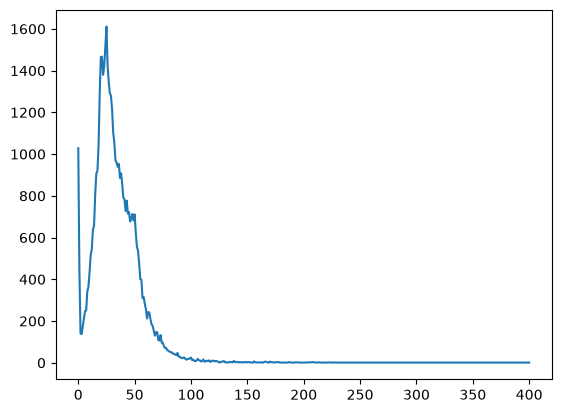

In [7]:
plt.plot(df["refs"].apply(len).value_counts().sort_index())
# plt.axis((0,100,0,100))
plt.show()


In [17]:
from typing import Callable

def filter_rows(df: pd.DataFrame) -> pd.Series:
    """Filtering criterion for accepting papers in the graph."""
    return (
        (df["abstract"] != "" )
        & (df["high_label_journal"] == True)
        & (df["manipulation"] == True)
        & (df["abstract"].apply(lambda abstract: "retracted" not in abstract))
    )

graph_df = df[filter_rows(df)].set_index("id")

def create_graph(df: pd.DataFrame, filter_function: Callable, keep_internal_references_only: bool) -> nx.DiGraph:
    """
    Creates a networkx directed graph from the papers in the dataframe.
    Filters papers to add to the graph by using the given filtering function.
    """

    graph = nx.DiGraph()
    filtered_df = df[filter_function(df)]

    for index, row in filtered_df.iterrows():
        graph.add_node(row["id"])

    for index, row in filtered_df.iterrows():
        for ref in row["refs"]:
            if not keep_internal_references_only or ref in graph.nodes: # important choice : do we accept adding new edges with papers that are not already in the graph ? 
                graph.add_edge(row["id"], ref)

    return graph

graph = create_graph(df, filter_rows, keep_internal_references_only=True)

print(graph)

DiGraph with 3644 nodes and 536 edges


In [5]:
components = list(sorted(nx.strongly_connected_components(graph), key=len, reverse=True))
print(len(list(components)))

# for cc in components:
#     print(graph.subgraph(cc))

3644


The citation graph is basically acyclic, it has no major strongly connected component. We can work with the biggest weakly connected component instead, by leaving out only a small fraction of nodes.

In [6]:
max_component = graph.subgraph(max(nx.weakly_connected_components(graph), key=len))
print(max_component)

DiGraph with 88 nodes and 125 edges


## Degree distribution

1     3381
2      181
3       40
4       13
5        7
6        4
7        5
8        2
9        3
10       3
11       1
12       1
13       0
14       0
15       0
16       0
17       0
18       1
19       0
20       0
21       0
22       0
23       0
24       0
25       1
26       0
27       0
28       0
29       0
30       0
31       0
32       1
Name: count, dtype: int64


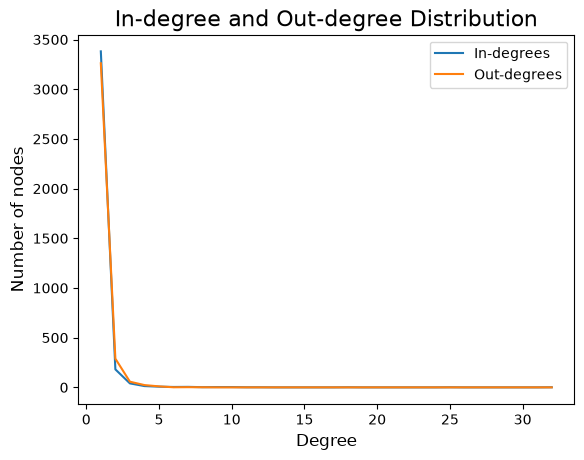

In [7]:
in_degrees: list[tuple[str, int]] = graph.in_degree
out_degrees: list[tuple[str, int]] = graph.out_degree

max_degree = max(list(in_degrees) + list(out_degrees), key=lambda degree: degree[1])[1]
degrees = pd.Series(range(1, max_degree+2))

# Convert in_degrees and out_degrees to pandas Series
in_degrees_series = pd.Series([degree[1] for degree in in_degrees]) +1 
out_degrees_series = pd.Series([degree[1] for degree in out_degrees]) +1 

# Count occurrences of each degree
in_degrees_count = in_degrees_series.value_counts().sort_index().reindex(degrees, fill_value=0)
out_degrees_count = out_degrees_series.value_counts().sort_index().reindex(degrees, fill_value=0)


print(in_degrees_count)

plt.plot(in_degrees_count, label="In-degrees")
plt.plot(out_degrees_count, label="Out-degrees")
plt.title("In-degree and Out-degree Distribution", fontsize=16)
plt.xlabel("Degree", fontsize=12)
plt.ylabel("Number of nodes", fontsize=12)
# plt.axis((5, 100, 0, 2000))

plt.legend()
plt.show()

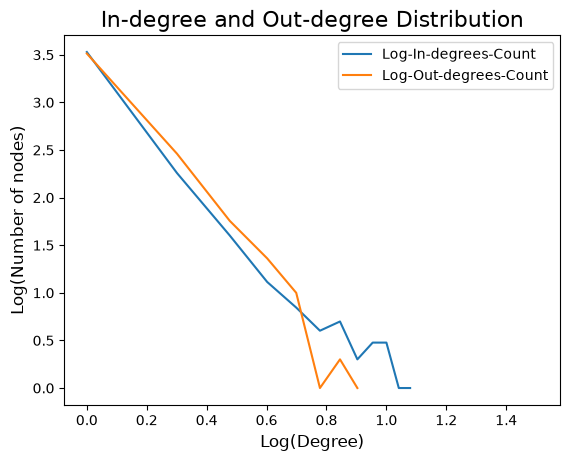

In [8]:
log_in_degrees_count = in_degrees_count.apply(np.log10)
log_out_degrees_count = out_degrees_count.apply(np.log10)
log_degrees = degrees.apply(np.log10)

plt.plot(log_degrees, log_in_degrees_count, label="Log-In-degrees-Count")
plt.plot(log_degrees, log_out_degrees_count, label="Log-Out-degrees-Count")
plt.title("In-degree and Out-degree Distribution", fontsize=16)
plt.xlabel("Log(Degree)", fontsize=12)
plt.ylabel("Log(Number of nodes)", fontsize=12)
plt.legend()
plt.show()

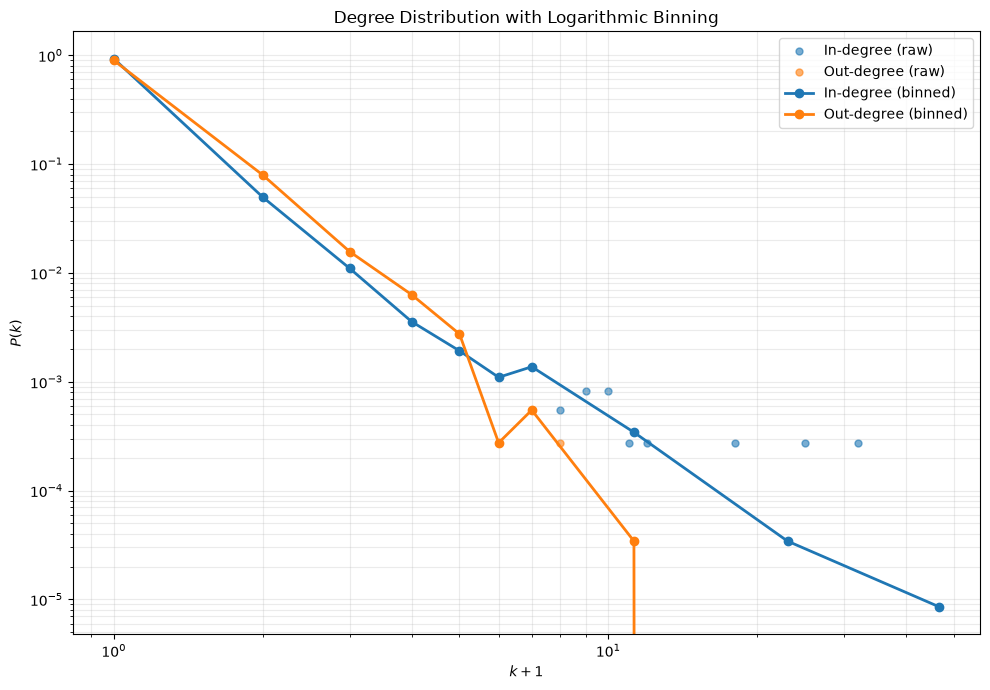

In [9]:
# ----------------------------
# Raw degree distributions
# ----------------------------

in_degree_values = np.array([degree for _, degree in in_degrees])
out_degree_values = np.array([degree for _, degree in out_degrees])

n = len(in_degree_values)

max_degree = max(
    in_degree_values.max(),
    out_degree_values.max()
)

# Count every degree, including degrees that don't occur
in_counts = (
    pd.Series(in_degree_values)
    .value_counts()
    .reindex(range(max_degree + 1), fill_value=0)
)

out_counts = (
    pd.Series(out_degree_values)
    .value_counts()
    .reindex(range(max_degree + 1), fill_value=0)
)


# ----------------------------
# Binning
# ----------------------------

# Bins are defined in u = k + 1
bin_edges = [1, 2, 3, 4, 5, 6, 7, 8, 16, 32, 64, 128]


def bin_distribution(counts, bin_edges, n):
    """
    Bin a degree distribution using the course's scheme.

    Returns:
        x: geometric mean of degrees in each bin (using k + 1)
        y: normalized count per unit bin width
    """
    x = []
    y = []

    for left, right in zip(bin_edges[:-1], bin_edges[1:]):

        # u = k + 1
        # Therefore k = u - 1
        degrees_in_bin = np.arange(left, right) - 1

        # Don't include degrees outside our actual distribution
        degrees_in_bin = degrees_in_bin[
            degrees_in_bin <= counts.index.max()
        ]

        if len(degrees_in_bin) == 0:
            continue

        # Number of nodes whose degree falls in this bin
        count = counts.loc[degrees_in_bin].sum()

        # IMPORTANT:
        # Normalize by the bin's width, NOT by the number of
        # observed degrees/nodes in the bin.
        width = right - left

        y.append(count / n / width)

        # Geometric mean of the u values covered by the bin
        u_values = np.arange(left, right)
        x.append(np.exp(np.mean(np.log(u_values))))

    return np.array(x), np.array(y)


in_bin_x, in_bin_y = bin_distribution(
    in_counts,
    bin_edges,
    n
)

out_bin_x, out_bin_y = bin_distribution(
    out_counts,
    bin_edges,
    n
)


# ----------------------------
# Raw distributions
# ----------------------------

# Raw P(k), shifted to k + 1
raw_x = np.arange(max_degree + 1) + 1

in_raw_y = in_counts.values / n
out_raw_y = out_counts.values / n


# ----------------------------
# Plot
# ----------------------------

plt.figure(figsize=(10, 7))

# Raw points
plt.scatter(
    raw_x,
    in_raw_y,
    s=25,
    alpha=0.6,
    label="In-degree (raw)"
)

plt.scatter(
    raw_x,
    out_raw_y,
    s=25,
    alpha=0.6,
    label="Out-degree (raw)"
)

# Binned distributions
plt.plot(
    in_bin_x,
    in_bin_y,
    marker="o",
    linewidth=2,
    label="In-degree (binned)"
)

plt.plot(
    out_bin_x,
    out_bin_y,
    marker="o",
    linewidth=2,
    label="Out-degree (binned)"
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel(r"$k+1$")
plt.ylabel(r"$P(k)$")
plt.title("Degree Distribution with Logarithmic Binning")

plt.legend()
plt.grid(True, which="both", alpha=0.25)

plt.tight_layout()
plt.show()

In [6]:
# report on how much of the graph is usable for text analysis
usable_abstracts = 0
nodes_number = len(graph.nodes)
df_indexed = df.set_index("id")

for node in graph.nodes:
    abstract = str(df_indexed.loc[node]["abstract"])
    if abstract != "":
        usable_abstracts += 1

assert usable_abstracts == nodes_number, "Some abstracts are missing from the nodes in the graph, so the textual analysis is not possible."

## Textual analysis 

In [7]:
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

# A model optimized for semantic similarity
model = SentenceTransformer("all-mpnet-base-v2", device=device)

c:\Users\aurel\repos\social_networks_project\finalproj\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1353.74it/s]


1
142.94038088900197
973


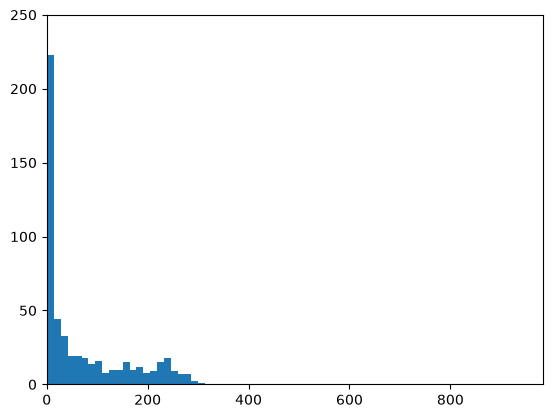

In [93]:
abstracts_word_length = df["abstract"].apply(lambda s: len(s.split(" ")))

print(abstracts_word_length.min())
print(abstracts_word_length.mean())
print(abstracts_word_length.max())

plt.hist(abstracts_word_length.value_counts().sort_index(), bins=1000)
plt.axis((0, abstracts_word_length.max()+10, 0, 250))
plt.show()


In [12]:
abstract1 = df["abstract"][0]

abstract2 = df["abstract"][2001]

# Compute embeddings
embeddings = model.encode([abstract1, abstract2])

# Cosine similarity
similarity = cosine_similarity(
    [embeddings[0]],
    [embeddings[1]]
)[0][0]

print(abstract1)
print(abstract2)
print(f"Similarity: {similarity:.4f}")

The prevailing concepts of intuitionistic fuzzy sets (IFSs), Pythagorean fuzzy sets (PFSs) and q-rung orthopair fuzzy sets (q-ROFSs) have numerous applications in various fields from real life. Unfortunately, these theories have their own limitations related to the membership and non-membership grades. To eradicate these restrictions, we introduce the novel concept of linear Diophantine fuzzy set (LDFS) with the addition of reference parameters. This idea removes the restrictions of existing methodologies and the decision maker (DM) can freely choose the grades without any limitations. This structure also categorizes the problem by changing the physical sense of reference parameters. We present some fundamental operations on linear Diophantine fuzzy sets (LDFSs). We present geometrical interpretation for different operations of LDFSs. We also introduce the novel concepts of linear Diophantine fuzzy topological space (LDFTS) and linear Diophantine fuzzy weighted geometric aggregation (L

In [9]:
def encode_long_document_tokenized(text: str, model: SentenceTransformer, max_tokens=250) -> np.ndarray:
    """
    Encodes a document by splitting it into chunks to avoid truncation.
    Then averages the chunk vector with respect to token length to give a better final representation.
    The final embedding is the normalized.
    """
    
    tokenizer = model.tokenizer
    tokens = tokenizer(
        text,
        add_special_tokens=False,
        truncation=False,
        return_attention_mask=False
    )["input_ids"]

    embeddings = []
    weights = []

    for i in range(0, len(tokens), max_tokens):
        chunk_tokens = tokens[i:i + max_tokens]
        assert (len(chunk_tokens) <= max_tokens)
        chunk_text = tokenizer.decode(chunk_tokens, skip_special_tokens=True)
        emb = model.encode(chunk_text, convert_to_numpy=True)
        embeddings.append(emb)
        weights.append(len(chunk_tokens))

    final_embedding = np.average(
        embeddings,
        axis=0,
        weights=weights
    )

    return final_embedding / np.linalg.norm(final_embedding)

In [10]:
embeddings = encode_long_document_tokenized([abstract1, abstract2], model, max_tokens=250)

# Cosine similarity
similarity = cosine_similarity(
    [embeddings[0]],
    [embeddings[1]]
)[0][0]

print(abstract1)
print(abstract2)
print(f"Similarity: {similarity:.4f}")

NameError: name 'abstract1' is not defined

In [18]:
# pre compute abstract embeddings for each node in the graph

# trying with title embedding instead of abstract 
graph_df["abstract_embedding"] = graph_df["title"].apply(
    encode_long_document_tokenized, (model, 250)
)

In [19]:
assert graph_df["abstract_embedding"].isnull().sum() == 0, f"{graph_df["abstract_embedding"].isnull().sum()} missing abstract embeddings"

In [20]:
def edge_similarity_score(edge: tuple[str, str], papers_with_embeddings_df: pd.DataFrame):
    embedding_u = papers_with_embeddings_df.loc[edge[0]]["abstract_embedding"]
    embedding_v = papers_with_embeddings_df.loc[edge[1]]["abstract_embedding"]
    # return float(cosine_similarity([embedding_u], [embedding_v])[0][0])

    # because embeddings are normalized, we can speed up the cosine similarity computation
    return np.dot(embedding_u, embedding_v)

def graph_similarity_scores(graph: nx.DiGraph, graph_df: pd.DataFrame) -> dict[tuple[str,str],float]:
    """
    For each edge of the graph linking 2 papers with abstracts, computes the similarity score.
    """
    similarity_scores: dict[tuple[str,str],float] = dict()
    for edge in graph.edges:
        similarity_scores[edge] = edge_similarity_score(edge, graph_df)
    return similarity_scores

def plot_similarity_scores(similarity_scores: dict[tuple[str,str],float], label: str):
    plt.hist(list(similarity_scores.values()), bins=50, range=(-1,1))
    plt.xlabel(label)
    plt.xlim(-1,1)
    plt.show()

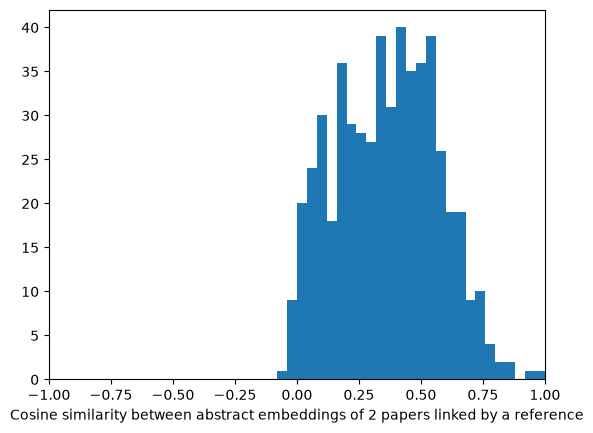

In [21]:
similarity_scores = graph_similarity_scores(graph, graph_df)
plot_similarity_scores(similarity_scores, "Cosine similarity between abstract embeddings of 2 papers linked by a reference")

In [15]:
print(similarity_scores)
print(graph_df.loc["W3092694791"]["abstract"])
print(graph_df.loc["W4304192948"]["abstract"])

{('W2973196180', 'W2811024336'): np.float64(0.6446415183205378), ('W3157286898', 'W3094500106'): np.float64(0.4345413971376644), ('W3213140656', 'W3006123093'): np.float64(0.8025247145282342), ('W3153436475', 'W2979513031'): np.float64(0.18886066885703295), ('W3182543535', 'W2918408501'): np.float64(0.6644400332120568), ('W4200127707', 'W3087870029'): np.float64(0.15412110027487247), ('W4200127707', 'W3155217306'): np.float64(0.2242338886688709), ('W3111163808', 'W2940320374'): np.float64(0.4683031952219223), ('W4200123330', 'W3183317227'): np.float64(0.16230343504414577), ('W3214607848', 'W3135202376'): np.float64(0.4616886692267764), ('W4200207905', 'W2913757370'): np.float64(0.3049355051761986), ('W4200207905', 'W3212233867'): np.float64(0.6464463677714118), ('W3188814857', 'W3128579993'): np.float64(0.44102455469880997), ('W3185661981', 'W2948361449'): np.float64(0.5322647620879104), ('W4205721122', 'W3124298694'): np.float64(0.09486688302007615), ('W4293354304', 'W4200127707'): np

KeyError: 'W3092694791'

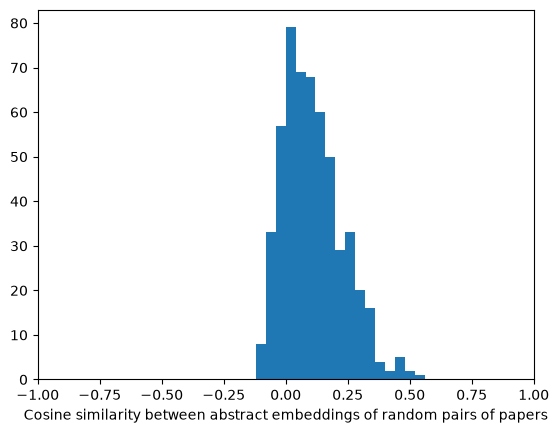

In [22]:
# first null model : similarity between randomly sampled pairs of papers
# the second null model should be a configuration model of the first graph, so the same papers are used, just different pairs

edges_count = len(graph.edges)
similarity_scores: dict[tuple[str,str],float] = dict()

for i in range(edges_count):
    node_u = np.random.choice(graph_df.index)
    node_v = np.random.choice(graph_df.index)
    false_edge = (node_u, node_v)
    if node_u == node_v or false_edge in graph.edges:
        i-=1
        continue

    similarity_scores[false_edge] = edge_similarity_score(false_edge, graph_df)

plot_similarity_scores(similarity_scores, "Cosine similarity between abstract embeddings of random pairs of papers")
   

In [41]:
# configuration_model_graph = nx.directed_edge_swap(
#     graph.copy(),
#     nswap=2*graph.number_of_edges(),
#     max_tries=10*graph.number_of_edges(),
# )

# similarity_scores = graph_similarity_scores(configuration_model_graph, graph_df)
# plot_similarity_scores(similarity_scores, "similarity scores distribution on configuration model")

In [104]:
dataframe_name = input("Filename to save the dataframe with embeddings as : ")
# graph_df.to_parquet("dataframes/"+dataframe_name+".parquet")
graph_df.to_pickle("dataframes/"+dataframe_name+".pickle")

In [108]:
graph_df_loaded = pd.read_pickle(f"dataframes/"+dataframe_name+".pickle")
graph_df.equals(graph_df_loaded)

True

In [ ]:
# output ids for these main paperd to query them with additional data 

# import json
# with open("seeds_ids.txt", "w") as f:
#     f.write(json.dumps({"ids": df["id"].to_list()}, indent=4))

In [ ]:
# merging partial reference records

# with open("data/raw/openalex/works.jsonl", "w", encoding="utf-8", errors="replace") as output:
#     with open("data/refreshed/seeds_references.jsonl", encoding="utf-8", errors="replace") as seeds:
#         output.write(seeds.read())
#     print("seeds")
#     with open("data/refreshed/justin_references.jsonl", encoding="utf-8", errors="replace") as papers:
#         output.write(papers.read())
#     print("justin")
#     with open("data/refreshed/partner_references.jsonl", encoding="utf-8", errors="replace") as papers:
#         output.write(papers.read())
#     print("partner")

seeds
justin
partner
